# 05 — MC Dropout e cálculo de VaR e ES

A LSTM prevê o retorno médio do próximo pregão. Para calcular VaR e ES, essa
previsão é combinada com os erros de calibração por simulação histórica
filtrada (Hull; White, 1998):

1. Cada erro de calibração, dado pelo retorno observado menos o previsto,
   é dividido pela volatilidade EWMA conhecida na origem, com λ = 0,94.
2. No teste, os cenários são obtidos por `previsão + escala EWMA × erro padronizado`.
3. Cada log-retorno é convertido em perda simples por `L = 1 − exp(r)`.
   VaR e ES são calculados nessa distribuição empírica.

A HMM-LSTM usa os erros do regime corrente quando há pelo menos 100 observações
na calibração; nos demais casos, usa o conjunto completo. A FHS-EWMA aplica a
mesma regra de escala com previsão de média zero. O MS-GARCH usa sua volatilidade
condicional e os resíduos dos cinco anos de desenvolvimento.

O MC Dropout é analisado separadamente como diagnóstico da incerteza da rede.

In [1]:
import importlib.util
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.features import ewma_volatility, get_b3_trading_days
from src.risk.var_es import empirical_var_es, losses_from_log_returns

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "reports" / "tables" / "walk_forward"
MSGARCH_DIR = PROJECT_ROOT / "reports" / "tables" / "msgarch"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})
NAMES = {"hmm_lstm": "HMM-LSTM", "lstm": "LSTM", "zero_mean_reference": "FHS-EWMA", "ms_garch": "MS-GARCH"}

forecasts = pd.concat([pd.read_parquet(p) for p in sorted(RESULTS_DIR.glob("forecasts_fold*.parquet"))],
                      ignore_index=True)
forecasts = pd.concat([forecasts, pd.read_parquet(MSGARCH_DIR / "forecasts_msgarch.parquet")], ignore_index=True)
calibration = pd.concat([pd.read_parquet(p) for p in sorted(RESULTS_DIR.glob("calibration_fold*.parquet"))],
                        ignore_index=True)
manifest = json.loads((RESULTS_DIR / "manifest.json").read_text(encoding="utf-8"))
n_states = {m["fold"]: m["n_states"] for m in manifest if m["model"] == "hmm_lstm"}

hmm = forecasts[(forecasts.model == "hmm_lstm") & (forecasts.confidence == .95)].set_index("target")
stress = hmm.regime == hmm.fold.map(n_states) - 1
print(f"{forecasts.target.nunique()} dias de teste; {stress.sum()} em regime de estresse "
      f"(estado de maior volatilidade do HMM na véspera)")

2717 dias de teste; 289 em regime de estresse (estado de maior volatilidade do HMM na véspera)


## Volatilidade EWMA da carteira

A EWMA atualiza a escala dos cenários conforme os retornos observados. As faixas
indicam os dias classificados no estado de maior volatilidade na véspera.

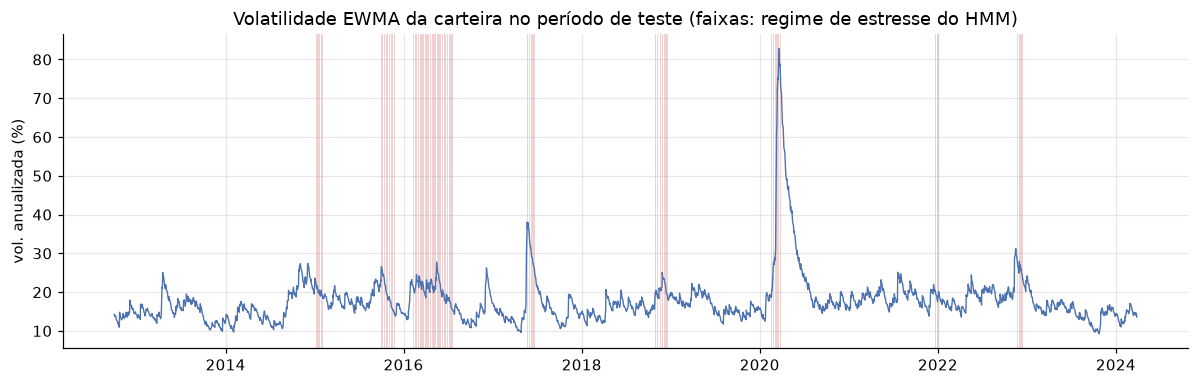

In [2]:
portfolio = pd.read_parquet(PROCESSED_DIR / "portfolio_return.parquet")
sessions = get_b3_trading_days(portfolio.index.min(), portfolio.index.max())
vol = ewma_volatility(portfolio.reindex(sessions).return_1d, lam=.94)
test = slice(forecasts.target.min(), forecasts.target.max())

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(vol.loc[test].index, vol.loc[test] * np.sqrt(252) * 100, lw=.9, color="#4C72B0")
for date in stress[stress].index:
    ax.axvspan(date, date + pd.Timedelta(days=1), color="#C44E52", alpha=.25, lw=0)
ax.set_ylabel("vol. anualizada (%)")
ax.set_title("Volatilidade EWMA da carteira no período de teste (faixas: regime de estresse do HMM)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_vol_ewma_e_estresse.png", bbox_inches="tight")

## Erros padronizados de calibração

A tabela compara a dispersão e as caudas dos erros entre regimes. Se a EWMA
representasse toda a variação de escala, seria esperado um desvio próximo de 1
e menor diferença entre os grupos.

In [3]:
cal = calibration.assign(z=(calibration.return_1d - calibration.prediction) / calibration.scale)
summary = cal.groupby("model").z.agg(desvio="std", assimetria=stats.skew,
                                     curtose_excesso=lambda x: stats.kurtosis(x)).round(2)
summary["n"] = cal.groupby("model").size()
display(summary)

hmm_cal = cal[cal.model == "hmm_lstm"].copy()
hmm_cal["estresse"] = hmm_cal.regime == hmm_cal.fold.map(n_states) - 1
print("Erros padronizados da HMM-LSTM, por regime na origem:")
hmm_cal.groupby("estresse").z.agg(n="size", desvio="std", q01=lambda x: x.quantile(.01),
                                  q05=lambda x: x.quantile(.05)).round(2)

,desvio,assimetria,curtose_excesso,n
model,,,,
hmm_lstm,1.05,-0.04,1.40,5557
lstm,1.05,-0.01,1.41,5557


Erros padronizados da HMM-LSTM, por regime na origem:


,n,desvio,q01,q05
estresse,,,,
False,5111,1.07,-2.50,-1.69
True,446,0.86,-1.95,-1.38


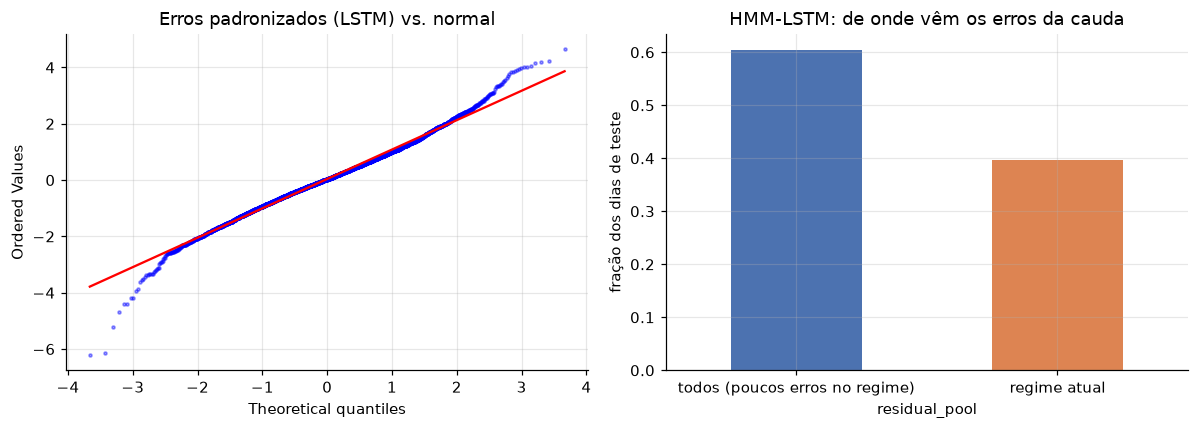

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
z = cal[cal.model == "lstm"].z
stats.probplot(z, dist="norm", plot=axes[0])
axes[0].set_title("Erros padronizados (LSTM) vs. normal")
axes[0].get_lines()[0].set(markersize=2, alpha=.4)
pools = forecasts[forecasts.model == "hmm_lstm"].drop_duplicates("target").residual_pool
pools = pools.map(lambda p: "regime atual" if p.startswith("regime") else "todos (poucos erros no regime)")
pools.value_counts(normalize=True).plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452"], rot=0)
axes[1].set_title("HMM-LSTM: de onde vêm os erros da cauda")
axes[1].set_ylabel("fração dos dias de teste")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_residuos_e_uso_da_cauda.png", bbox_inches="tight")

Os erros padronizados têm caudas mais pesadas que a normal, o que favorece
o uso da distribuição empírica. Em parte dos dias, a calibração não reúne 100
erros do regime corrente e a HMM-LSTM usa o conjunto completo. Isso ocorre
em todos os dias classificados como estresse nesta execução.

## Previsão média nos dias de estresse

No estresse, as duas redes usam seus conjuntos completos de erros. A comparação
a seguir examina o deslocamento dos cenários associado à média prevista.

In [5]:
means = []
for model in ("hmm_lstm", "lstm"):
    d = forecasts[(forecasts.model == model) & (forecasts.confidence == .95)].set_index("target")
    means.append({"modelo": NAMES[model],
                  "prevista no estresse (%)": d.prediction[stress].mean() * 100,
                  "prevista nos demais (%)": d.prediction[~stress].mean() * 100,
                  "realizada no estresse (%)": d.actual_log_return[stress].mean() * 100})
pd.DataFrame(means).set_index("modelo").round(3)

,prevista no estresse (%),prevista nos demais (%),realizada no estresse (%)
modelo,,,
HMM-LSTM,0.165,-0.011,-0.097
LSTM,0.042,0.004,-0.097


A HMM-LSTM prevê retorno médio positivo no estresse, enquanto o retorno médio
observado nesses dias de teste é negativo. A previsão positiva desloca os
cenários de perda para baixo e pode contribuir para as violações adicionais.
Uma hipótese é que o estado de alta volatilidade no treino também inclua
recuperações do mercado, como as do fim de 2008 e de 2020.

O notebook 07 mostra que as colunas de regime têm contribuição direta pequena
para a previsão. Além disso, a diferença de escore entre as duas redes no
estresse não é significativa nos testes do notebook 06.

## Dispersão das previsões com MC Dropout

São feitas mil previsões por entrada com dropout ativo. A dispersão resultante
descreve a sensibilidade da previsão de média às máscaras da rede. Ela não
representa, por si só, a variabilidade dos retornos (Kendall; Gal, 2017).

In [6]:
nets = forecasts[forecasts.model.isin(["lstm", "hmm_lstm"]) & (forecasts.confidence == .95)].copy()
nets["erro_abs"] = (nets.actual_log_return - nets.prediction).abs()
diag = nets.groupby("model").apply(lambda d: pd.Series({
    "dp_dropout_mediano_%": d.dropout_sd.median() * 100,
    "vol_ewma_mediana_%": d.scale.median() * 100,
    "razao_mediana": (d.dropout_sd / d.scale).median(),
    "corr_spearman_dp_vs_erro": stats.spearmanr(d.dropout_sd, d.erro_abs).statistic,
}), include_groups=False).round(3)
diag

,dp_dropout_mediano_%,vol_ewma_mediana_%,razao_mediana,corr_spearman_dp_vs_erro
model,,,,
hmm_lstm,0.089,1.045,0.080,0.027
lstm,0.072,1.045,0.069,-0.011


Nesta execução, a dispersão do dropout é pequena em relação à volatilidade
diária e tem pouca relação com o erro realizado. Seu uso isolado no cálculo
de risco produziria estimativas muito menores. Por isso, ela permanece como
diagnóstico. Sua combinação com os erros de calibração exigiria cuidado para
não contar novamente efeitos que esses erros já incorporam.

## Cenários para 12 de março de 2020

Na véspera, o HMM indicava estresse e a EWMA havia dobrado em relação ao início
do mês. O gráfico compara os cenários de perda, o VaR e o ES a 99% e a perda observada.

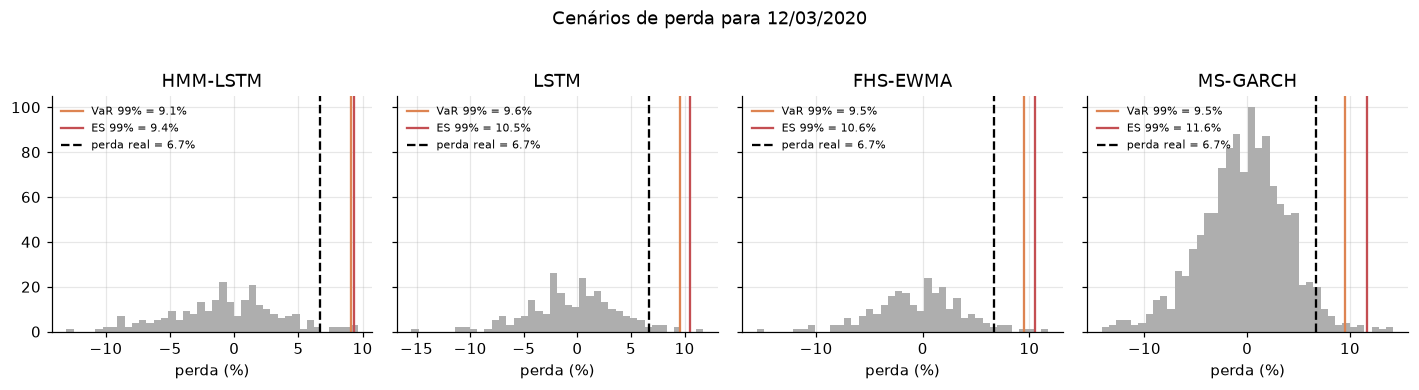

In [7]:
spec = importlib.util.spec_from_file_location("evaluate", PROJECT_ROOT / "scripts" / "evaluate_walk_forward.py")
evaluate = importlib.util.module_from_spec(spec); spec.loader.exec_module(evaluate)

DAY = pd.Timestamp("2020-03-12")
fold = int(forecasts.loc[forecasts.target == DAY, "fold"].iloc[0])
base = forecasts[(forecasts.fold == fold) & (forecasts.model != "ms_garch")]
full_sessions = get_b3_trading_days(calibration.origin.min(), forecasts.target.max())
days = evaluate.fhs_scenarios(base[base.target == DAY], calibration[calibration.fold == fold], manifest,
                              sessions=full_sessions, min_regime_pool=100)
msg = forecasts[(forecasts.model == "ms_garch") & (forecasts.target == DAY)]
days["ms_garch"] = evaluate.msgarch_scenarios(msg)

realized = float(base.loc[base.target == DAY, "actual_loss"].iloc[0])
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, model in zip(axes, ("hmm_lstm", "lstm", "zero_mean_reference", "ms_garch")):
    scenarios = losses_from_log_returns(days[model][0][1]) * 100
    risk = empirical_var_es(scenarios / 100, .99)
    ax.hist(scenarios, bins=40, color="#8C8C8C", alpha=.7)
    ax.axvline(risk["var"] * 100, color="#DD8452", label=f"VaR 99% = {risk['var']:.1%}")
    ax.axvline(risk["es"] * 100, color="#C44E52", label=f"ES 99% = {risk['es']:.1%}")
    ax.axvline(realized * 100, color="black", ls="--", label=f"perda real = {realized:.1%}")
    ax.set_title(NAMES[model]); ax.set_xlabel("perda (%)")
    ax.legend(fontsize=7, frameon=False)
fig.suptitle(f"Cenários de perda para {DAY:%d/%m/%Y}", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_cenarios_12mar2020.png", bbox_inches="tight")

## VaR a 99% ao longo do teste

Perdas diárias (pontos) contra o VaR a 99% da HMM-LSTM e do MS-GARCH. Os pontos acima da
linha são violações.

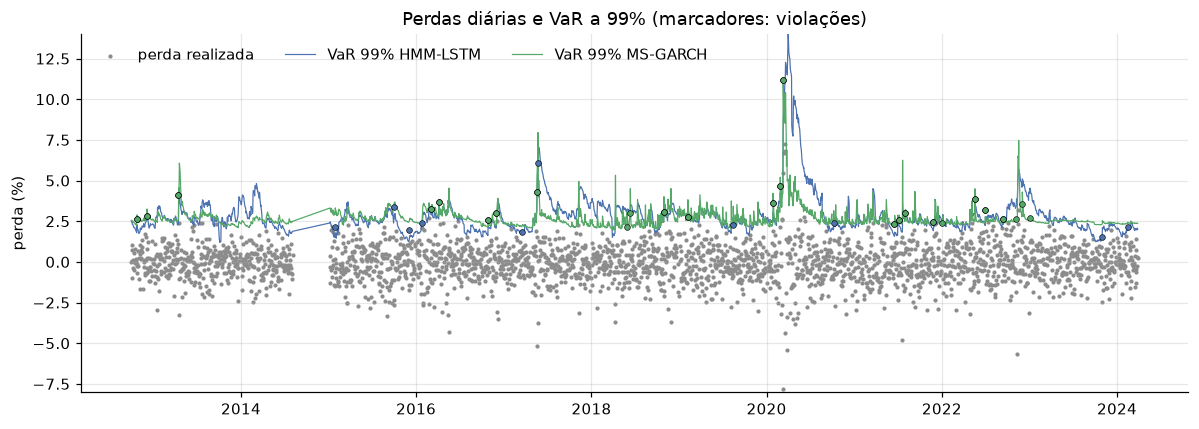

In [8]:
level = .99
fig, ax = plt.subplots(figsize=(11, 4))
loss = hmm.actual_loss * 100
ax.scatter(loss.index, loss, s=3, color="#8C8C8C", label="perda realizada")
for model, color in (("hmm_lstm", "#4C72B0"), ("ms_garch", "#55A868")):
    s = forecasts[(forecasts.model == model) & (forecasts.confidence == level)].set_index("target").sort_index()
    ax.plot(s.index, s["var"] * 100, lw=.8, color=color, label=f"VaR 99% {NAMES[model]}")
    hits = s[s.actual_loss > s["var"]]
    ax.scatter(hits.index, hits.actual_loss * 100, s=14, color=color, edgecolor="black", lw=.4, zorder=3)
ax.set_ylim(-8, 14)
ax.set_ylabel("perda (%)")
ax.set_title("Perdas diárias e VaR a 99% (marcadores: violações)")
ax.legend(frameon=False, ncol=3, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_var99_no_tempo.png", bbox_inches="tight")

In [9]:
var_levels = (forecasts[forecasts.confidence == .99].groupby("model")["var"]
              .describe(percentiles=[.5, .95])[["mean", "50%", "95%", "max"]] * 100).round(2)
var_levels.index = var_levels.index.map(NAMES)
var_levels.columns = ["média %", "mediana %", "p95 %", "máximo %"]
var_levels

,média %,mediana %,p95 %,máximo %
model,,,,
HMM-LSTM,2.86,2.62,4.61,14.04
LSTM,2.87,2.61,4.62,13.87
MS-GARCH,2.69,2.53,3.52,10.92
FHS-EWMA,2.93,2.63,4.67,15.26


## Discussão das estimativas

- A escala EWMA permite que os cenários acompanhem a volatilidade ao longo do teste.
- A dispersão do MC Dropout é pequena diante da variação diária dos retornos e
  foi mantida como diagnóstico.
- A calibração de um ano limita o número de erros disponíveis por estado.
  No estresse, a HMM-LSTM usa sempre o conjunto completo de erros.
- A média positiva prevista pela HMM-LSTM no estresse reduz as estimativas de
  perda. O notebook 06 avalia as consequências para a cobertura e os escores.
- O percentil 95 do VaR a 99% é cerca de 3,5% no MS-GARCH e de 4,6% nos modelos
  com EWMA. Mesmo com estimativas menores nesse ponto da distribuição, o
  MS-GARCH apresenta melhor cobertura nesta amostra.